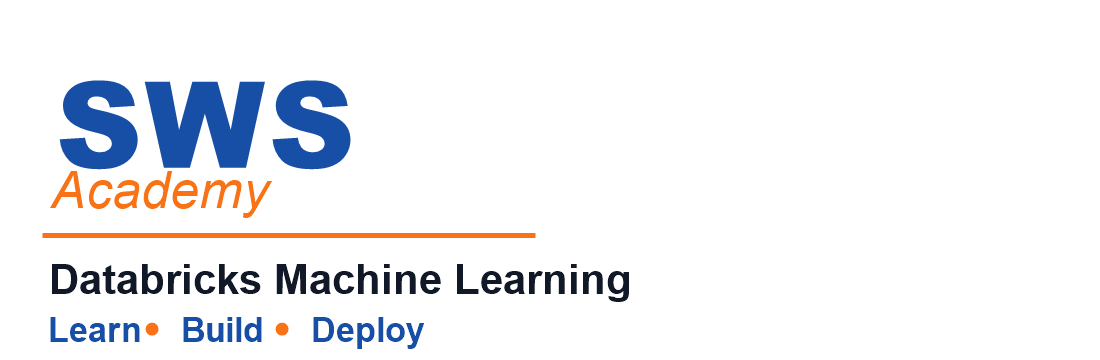


# Batch Deployment

Batch inference is the most common way of deploying machine learning models.  This lesson introduces various strategies for deploying models using batch including Spark. In addition, we will show how to enable optimizations for Delta tables.

**Learning Objectives:**

*By the end of this demo you will be able to:*

* Load a logged Model Registry model using `pyfunc`.

* Compute predictions using `pyfunc` APIs.

* Perform batch inference using Feature Engineering's `score_batch` method.

* Materialize predictions into inference tables (Delta Lake).

* Perform common write optimizations like liquid clustering, predictive optimization to maximize data skipping and on inference tables.

## REQUIRED - SELECT CLASSIC COMPUTE
Before executing cells in this notebook, please select your classic compute cluster in the lab. Be aware that **Serverless** is enabled by default.

Follow these steps to select the classic compute cluster:
1. Navigate to the top-right of this notebook and click the drop-down menu to select your cluster. By default, the notebook will use **Serverless**.

2. If your cluster is available, select it and continue to the next cell. If the cluster is not shown:

   - Click **More** in the drop-down.

   - In the **Attach to an existing compute resource** window, use the first drop-down to select your unique cluster.

**NOTE:** If your cluster has terminated, you might need to restart it in order to select it. To do this:

1. Right-click on **Compute** in the left navigation pane and select *Open in new tab*.

2. Find the triangle icon to the right of your compute cluster name and click it.

3. Wait a few minutes for the cluster to start.

4. Once the cluster is running, complete the steps above to select your cluster.

## Requirements

Please review the following requirements before starting the lesson:

* To run this notebook, you need to use one of the following Databricks runtime(s): **17.3.x-cpu-ml-scala2.13**

**🚨 Prerequisites:** 
* **Feature Engineering** and **Feature Store** are not the focus of this lesson. This course expect that you already know these topics. If not, you can check the **Data Preparation for Machine Learning** course.

* Model development with MLFlow is not in the scope of this course. If you need to refresh your knowledge about model tracking and logging, you can check the **Machine Learning Model Development** course.


## Classroom Setup

Before starting the demo, run the provided classroom setup script. This script will define configuration variables necessary for the demo. Execute the following cell:

In [ ]:
%run ../Includes/Classroom-Setup-2.1

**Other Conventions:**

Throughout this demo, we'll refer to the object `SA`. This object, provided by SWSAcademy, contains variables such as your username, catalog name, schema name, working directory, and dataset locations. Run the code block below to view these details:

In [ ]:
print(f"Username:          {SA.username}")
print(f"Catalog Name:      {SA.catalog_name}")
print(f"Schema Name:       {SA.schema_name}")
print(f"Working Directory: {SA.paths.working_dir}")
print(f"User DB Location:  {SA.paths.datasets}")

## Data Preparation

For this demonstration, we will utilize a fictional dataset from a Telecom Company, which includes customer information. This dataset encompasses **customer demographics**, including gender, as well as internet subscription details such as subscription plans and payment methods.

After loading the dataset, we will perform simple **data cleaning and feature selection**. 

In the final step, we will split the dataset into **features** and **response** sets.

In [ ]:
from pyspark.sql.functions import col

# Load dataset with spark
shared_volume_name = 'telco' # From Marketplace
csv_name = 'telco-customer-churn-missing' # CSV file name
dataset_p_telco = f"{SA.paths.datasets.telco}/{shared_volume_name}/{csv_name}.csv" # Full path

# features to use
primary_key = "customerID"
response = "Churn"
features = ["SeniorCitizen", "tenure", "MonthlyCharges", "TotalCharges"] # Keeping numerical only for simplicity and demo purposes

# Read dataset (and drop nan)
telco_df = spark.read.csv(dataset_p_telco, inferSchema=True, header=True, multiLine=True, escape='"')\
            .withColumn("TotalCharges", F.expr("try_cast(trim(TotalCharges) as double)"))\
            .withColumn("SeniorCitizen", col("SeniorCitizen").cast('double'))\
            .withColumn("Tenure", col("tenure").cast('double'))\
            .na.drop(how='any')

# Split with 80 percent of the data in train_df and 20 percent of the data in test_df
train_df, test_df = telco_df.randomSplit([.8, .2], seed=42)

# Separate features and ground-truth
features_df = train_df.select(primary_key, *features)
response_df = train_df.select(primary_key, response)

# review the features dataset
display(features_df)


## Batch Deployment - Without Feature Store

This demo will cover two main batch deployment methods. The first method is deploying models without a feature table. For the second method, we will use a feature table to train the model and later use the feature table for inference.


### Setup Model Registry with UC

Before we start model deployment, we need to fit and register a model. In this demo, **we will log models to Unity Catalog**, which means first we need to setup the **MLflow Model Registry URI**.

In [ ]:
import mlflow

# Point to UC model registry
mlflow.set_registry_uri("databricks-uc")
client = mlflow.MlflowClient()

# helper function that we will use for getting latest version of a model
def get_latest_model_version(model_name):
    """Helper function to get latest model version"""
    model_version_infos = client.search_model_versions("name = '%s'" % model_name)
    return max([model_version_info.version for model_version_info in model_version_infos])

### Fit and Register a Model with UC

In [ ]:
# Train a sklearn Decision Tree Classification model
from sklearn.tree import DecisionTreeClassifier
from mlflow.models import infer_signature

# Convert data to pandas dataframes
X_train_pdf = features_df.drop(primary_key).toPandas()
Y_train_pdf = response_df.drop(primary_key).toPandas()
clf = DecisionTreeClassifier(max_depth=3, random_state=42)

# Use 3-level namespace for model name
model_name = f"{SA.catalog_name}.{SA.schema_name}.ml_model" 

with mlflow.start_run(run_name="Model-Batch-Deployment-Demo") as mlflow_run:

    # Enable automatic logging of input samples, metrics, parameters, and models
    mlflow.sklearn.autolog(
        log_input_examples=True,
        log_models=False,
        log_post_training_metrics=True,
        silent=True)
    
    clf.fit(X_train_pdf, Y_train_pdf)

    # Log model and push to registry
    signature = infer_signature(X_train_pdf, Y_train_pdf)
    mlflow.sklearn.log_model(
        clf,
        artifact_path="decision_tree",
        signature=signature,
        registered_model_name=model_name
    )

    # Set model alias (i.e. Baseline)
    client.set_registered_model_alias(model_name, "Baseline", get_latest_model_version(model_name))


### Use the Model for Inference 

Now that our model is ready in model registry, we can use it for inference. In this section we will use the model for inference directly on a spark dataframe, which is called **batch inference**.

#### Load the Model

Loading a model from UC-based model registry is done by getting a model using **alias** and **version**. 

After loading the model, we will create a **`spark_udf`** from the model.

In [ ]:
latest_model_version = client.get_model_version_by_alias(name=model_name, alias="baseline").version
model_uri = f"models:/{model_name}/{latest_model_version}" # Should be version 1
# model_uri = f"models:/{model_name}@baseline # uri can also point to @alias
predict_func = mlflow.pyfunc.spark_udf(
    spark,
    model_uri)

#### Inference

Next, we will simply use the created function for inference.

In [ ]:
# prepare test dataset
test_features_df = test_df.select(primary_key, *features)

# make prediction
prediction_df = test_features_df.withColumn("prediction", predict_func(*test_features_df.drop(primary_key).columns))

display(prediction_df)

## Batch Deployment - With Feature Store 

In the previous section we trained and registered a model using Spark dataframe. In some cases, you will need to use features from a feature store for training and inference. 

In this section we will demonstrate how to train and deploy a model using Feature Store.

### Create Feature Table

Let's create a feature table based on the `features_df` that we created before. Please note that we will be using **Feature Store with Unity Catalog**, which means we need to use **`FeatureEngineeringClient`**.

In [ ]:
from databricks.feature_engineering import FeatureEngineeringClient

# prepare feature set
features_df_all = telco_df.select(primary_key, *features)

# feature table definition
fe = FeatureEngineeringClient()
feature_table_name = f"{SA.catalog_name}.{SA.schema_name}.features"

#drop table if exists
try:
    fe.drop_table(name=feature_table_name)
except:
    pass

# Create feature table
fe.create_table(
    name=feature_table_name,
    df=features_df_all,
    primary_keys=[primary_key],
    description="Example feature table"
)

### Setup Feature Lookups

In order to create a training set from the feature table, we need to define a *feature lookup*. This will be used for creating training set from the feature table. 

Note that the **`lookup_key`** is used for matching records in feature table.

In [ ]:
# Create training set based on feature lookup
from databricks.feature_engineering import FeatureLookup

fl_handle = FeatureLookup(
    table_name=feature_table_name,
    lookup_key=[primary_key]
)

training_set_spec = fe.create_training_set(
    df=response_df,
    label=response,
    feature_lookups=[fl_handle],
    exclude_columns=[primary_key]
)

# Load training dataframe based on defined feature-lookup specification
training_df = training_set_spec.load_df()

### Fit and Register a Model with UC using Feature Table

After creating the training set, **model training and registering is the same as the previous step**.

In [ ]:
import warnings
from mlflow.types.utils import _infer_schema
    
    
# Convert data to pandas dataframes
X_train_pdf2 = training_df.drop(primary_key, response).toPandas()
Y_train_pdf2 = training_df.select(response).toPandas()
clf2 = DecisionTreeClassifier(max_depth=3, random_state=42)


with mlflow.start_run(run_name="Model-Batch-Deployment-Demo-With-FS") as mlflow_run:

    # Enable automatic logging of input samples, metrics, parameters, and models
    mlflow.sklearn.autolog(
        log_input_examples=True,
        log_models=False,
        log_post_training_metrics=True,
        silent=True)
    
    clf2.fit(X_train_pdf, Y_train_pdf)

    # Infer output schema
    try:
      output_schema = _infer_schema(Y_train_pdf)
    except Exception as e:
      warnings.warn(f"Could not infer model output schema: {e}")
      output_schema = None
    
    # Log using feature engineering client and push to registry
    fe.log_model(
        model=clf2,
        artifact_path="decision_tree",
        flavor=mlflow.sklearn,
        training_set=training_set_spec,
        output_schema=output_schema,
        registered_model_name=model_name
    )

    # Set model alias (i.e. Champion)
    client.set_registered_model_alias(model_name, "Champion", get_latest_model_version(model_name))


### Use the Model for Inference

Inference for models that are registered with a Feature Store table are different than inference with a Spark DataFrame. For inference, we will use **feature engineering client's `.score_batch()` method**. This method takes **a model URI** and **DataFrame with a primary key**.

> **How does the function know which feature table to use?** If you visit **Artifacts** section of registered model, you will see a **`data`** folder is registered with the model. Also, model file includes **`data: data/feature_store`** statement to define feature data.

In [ ]:
champion_model_uri = f"models:/{model_name}@champion"

In [ ]:
# prepare lookup dataset
lookup_df = test_df.select("customerID")

# predict in batch using lookup df
prediction_fe_df = fe.score_batch(
    model_uri=champion_model_uri,
    df=lookup_df,
    result_type='string')

Join with the `test_df` DataFrame to compare the `prediction` and `churn` columns. Remember, we are _predicting_ churn in this scenario.

In [ ]:
# Join predction_df_df and test_df on customerID and only keep columns from prediction_fe_df
prediction_fe_df = prediction_fe_df.join(test_df.select(["customerID","Churn"]), on = "customerID", how = "left")
display(prediction_fe_df)

In [ ]:
display(prediction_fe_df)

## Performance Considerations

There are many possible (write) optimizations that Delta Lake can offer such as:
- **Partitioning:** stores data associated with different categorical values in different directories.
- **Z-Ordering (Legacy):** colocates related information in the same set of files.
- **Liquid Clustering (Recommended):** replaces both above-mentioned  methods to simplify data layout decisions and optimize query performance.
- **Predictive Optimizations:** removes the need to manually manage maintenance operations for Delta tables on Databricks.

In this demo, we will show the last two options; liquid clustering and predictive optimization.

In [ ]:
spark.sql(f"USE CATALOG {SA.catalog_name}")
spark.sql(f"USE SCHEMA {SA.schema_name}")

**Enable Predictive Optimization** at the schema level (can also be done at catalog level) is automatically enabled as a part of the Workspace setup and you do not have the proper permissions to enable it or disable it at the schema level as a user of this demo. However, the code to do so is provided here for completeness: 

```spark.sql(f"ALTER SCHEMA {SA.catalog_name}.{SA.schema_name} ENABLE PREDICTIVE OPTIMIZATION;")```

Create inference table (where batch scoring jobs would be materialized) and enable liquid clustering on using `CLUSTER BY`

In [ ]:
%sql
CREATE OR REPLACE TABLE batch_inference(
  customerID STRING
 ,Churn STRING
 ,SeniorCitizen DOUBLE
 ,tenure DOUBLE
 ,MonthlyCharges DOUBLE
 ,TotalCharges DOUBLE
 ,prediction STRING)
CLUSTER BY (customerID, tenure)

In [ ]:
(
  prediction_fe_df.write
  .mode("append")
  .option("mergeSchema", True)
  .saveAsTable(f"{SA.catalog_name}.{SA.schema_name}.batch_inference")
)

Manually optimize table

In [ ]:
%sql
ANALYZE TABLE batch_inference COMPUTE STATISTICS FOR ALL COLUMNS;
OPTIMIZE batch_inference

Review the `batch_inference` table.

In [ ]:
%sql
SELECT 
* EXCEPT(Churn),
Churn
FROM batch_inference


## Conclusion

In this demo, we presented two main batch deployment methods using MLflow for model tracking and logging with Unity Catalog. In the first approach, we trained and registered a model without a feature table, reloading it for inference through a Spark UDF. The second method involved training a model with a feature table, registering it in the model registry, and using a look-up key for data retrieval during inference.

<div style="border-top: 1px solid #E5E7EB; margin-top: 32px; padding: 12px 0; color: #4B5563; font-size: 13px; font-family: Arial, Helvetica, sans-serif; line-height: 1.5;">
  <div><strong>SWS Academy</strong> &nbsp;|&nbsp; Databricks AI &amp; Machine Learning Course</div>
  <div>&copy; 2026 SWS Academy. All rights reserved. Unauthorized reproduction or distribution is prohibited.</div>
</div>